# Kidney CT Image Classification — Kaggle / PyTorch

**Four classes:** Cyst, Normal, Stone, and Tumor.

> **Research prototype only.** This notebook is not a medical device and must not be used to diagnose, exclude, or guide treatment of disease.

## Run this notebook in Kaggle

1. Open the notebook in Kaggle and select **Settings → Accelerator → GPU** (T4 is suitable).
2. Add the `Kidney_Stone_Datasets` dataset to the notebook using **Add Input**.
3. The notebook automatically searches `/kaggle/input` for `Split_Images/train`, `val`, and `test`. You normally do not need to edit a path.
4. Run the cells from top to bottom. The trained model and reports are saved under `/kaggle/working/`.

**Why this version is different:** it removes Google Colab/Google Drive code, avoids extra package installs, uses GPU mixed precision when available, keeps DataLoader workers persistent, saves checkpoints after every epoch, and calculates class-wise test metrics.

**About the `.h5` file shown in your Kaggle input:** `best_kidney_model_mobilenetv2.h5` appears to be a Keras/HDF5 MobileNetV2 model. This notebook trains a PyTorch ResNet50 model, so it does not load that file. The two model formats/architectures are not interchangeable.

In [1]:
# 1. Imports and environment
import os
import copy
import time
import random
import json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import ImageFile

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    roc_auc_score,
)

ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Allow cuDNN to select faster convolution algorithms for a fixed image size.
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

# Limit CPU thread oversubscription, which can slow notebook workloads.
torch.set_num_threads(min(4, os.cpu_count() or 1))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU is not active. In Kaggle, open Settings → Accelerator → GPU, then restart the session.")


PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


## 2. Find the Kaggle dataset automatically

Expected structure:

```text
/kaggle/input/<dataset-name>/Split_Images/
    train/Cyst, Normal, Stone, Tumor/
    val/Cyst, Normal, Stone, Tumor/
    test/Cyst, Normal, Stone, Tumor/
```

The folder name may be capitalized or lowercase in the Kaggle dataset title; the search below checks the actual folder structure.

In [2]:
# 2. Dataset paths — normally no manual path editing is needed
INPUT_ROOT = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SPLIT_NAMES = ("train", "val", "test")


def find_split_images_root(input_root: Path) -> Path:
    if not input_root.exists():
        raise FileNotFoundError(
            f"{input_root} was not found. This notebook is intended to run on Kaggle."
        )

    candidates = []
    for candidate in input_root.rglob("Split_Images"):
        if candidate.is_dir() and all((candidate / split).is_dir() for split in SPLIT_NAMES):
            candidates.append(candidate)

    # Also allow a dataset folder where train/val/test are directly inside it.
    if not candidates:
        for candidate in input_root.iterdir():
            if candidate.is_dir() and all((candidate / split).is_dir() for split in SPLIT_NAMES):
                candidates.append(candidate)

    if len(candidates) == 0:
        visible = [str(p) for p in input_root.iterdir()]
        raise FileNotFoundError(
            "Could not find a folder containing train, val, and test. "
            "Expected .../Split_Images/{train,val,test}. Items under /kaggle/input:\n"
            + "\n".join(visible)
        )

    if len(candidates) > 1:
        print("More than one matching dataset folder was found:")
        for p in candidates:
            print(" -", p)
        print("Using the first match. Set DATA_ROOT manually below if this is not your dataset.")

    return candidates[0]


DATA_ROOT = find_split_images_root(INPUT_ROOT)
# Optional manual override, e.g. DATA_ROOT = Path('/kaggle/input/kidney-stone-datasets/Split_Images')
# DATA_ROOT = Path("/kaggle/input/your-dataset-name/Split_Images")

TRAIN_DIR = DATA_ROOT / "train"
VAL_DIR = DATA_ROOT / "val"
TEST_DIR = DATA_ROOT / "test"

print("Using dataset:", DATA_ROOT)
for split_dir in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    print(split_dir, "exists:", split_dir.is_dir())


Using dataset: /kaggle/input/datasets/iamiqbalshigri/kidney-stone-datasets/Split_Images
/kaggle/input/datasets/iamiqbalshigri/kidney-stone-datasets/Split_Images/train exists: True
/kaggle/input/datasets/iamiqbalshigri/kidney-stone-datasets/Split_Images/val exists: True
/kaggle/input/datasets/iamiqbalshigri/kidney-stone-datasets/Split_Images/test exists: True


In [3]:
# 3. Training configuration
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_EPOCHS_HEAD = 6       # classifier head only
NUM_EPOCHS_FINETUNE = 6   # unfreeze ResNet layer4 + classifier
PATIENCE = 3              # early stopping patience
LR_HEAD = 1e-3
LR_FINETUNE = 1e-5
WEIGHT_DECAY = 1e-4

# Kaggle commonly supports 2 workers. If your notebook still stalls while
# loading images, change this to 0 (more conservative, sometimes slower).
NUM_WORKERS = 2
PIN_MEMORY = device.type == "cuda"

CLASS_NAMES_EXPECTED = {"Cyst", "Normal", "Stone", "Tumor"}
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

print("Batch size:", BATCH_SIZE)
print("DataLoader workers:", NUM_WORKERS)
print("Mixed precision:", USE_AMP)


Batch size: 32
DataLoader workers: 2
Mixed precision: True


## 4. Check split folders and class counts

`ImageFolder` assigns class IDs in alphabetical order. The code checks that all three splits contain the same four classes and that no class folder is empty.

In [5]:
# 4. Dataset transforms and datasets
# Keep augmentation moderate for medical images. No horizontal flip is used.
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(degrees=7),
    transforms.ColorJitter(brightness=0.08, contrast=0.08),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_dataset = datasets.ImageFolder(str(TRAIN_DIR), transform=train_transform)
val_dataset = datasets.ImageFolder(str(VAL_DIR), transform=eval_transform)
test_dataset = datasets.ImageFolder(str(TEST_DIR), transform=eval_transform)

CLASS_NAMES = train_dataset.classes
NUM_CLASSES = len(CLASS_NAMES)

if set(CLASS_NAMES) != CLASS_NAMES_EXPECTED:
    raise ValueError(
        f"Expected class folders {sorted(CLASS_NAMES_EXPECTED)}, but found {CLASS_NAMES}. "
        "Check the folder names in train/."
    )

for split_name, dataset in (("val", val_dataset), ("test", test_dataset)):
    if dataset.classes != CLASS_NAMES:
        raise ValueError(
            f"Class mismatch in {split_name}: {dataset.classes}; expected {CLASS_NAMES}."
        )


def count_by_class(dataset):
    counts = Counter(dataset.targets)
    return {name: counts.get(idx, 0) for idx, name in enumerate(dataset.classes)}

print("Class order (label IDs):", dict(enumerate(CLASS_NAMES)))
for split_name, dataset in (("train", train_dataset), ("val", val_dataset), ("test", test_dataset)):
    counts = count_by_class(dataset)
    print(f"{split_name:>5} | total={len(dataset):,} | " + " | ".join(f"{k}={v:,}" for k, v in counts.items()))
    if len(dataset) == 0 or any(v == 0 for v in counts.values()):
        raise ValueError(f"The {split_name} split is empty or has a class with zero images: {counts}")


Class order (label IDs): {0: 'Cyst', 1: 'Normal', 2: 'Stone', 3: 'Tumor'}
train | total=8,710 | Cyst=2,596 | Normal=3,553 | Stone=963 | Tumor=1,598
  val | total=2,487 | Cyst=741 | Normal=1,015 | Stone=275 | Tumor=456
 test | total=1,248 | Cyst=371 | Normal=509 | Stone=139 | Tumor=229


In [6]:
# 5. DataLoaders
# persistent_workers avoids restarting workers at every epoch. If NUM_WORKERS=0,
# the worker-only options are omitted automatically.
loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "pin_memory": PIN_MEMORY,
}
if NUM_WORKERS > 0:
    loader_kwargs.update({
        "num_workers": NUM_WORKERS,
        "persistent_workers": True,
        "prefetch_factor": 2,
    })
else:
    loader_kwargs["num_workers"] = 0

train_loader = DataLoader(train_dataset, shuffle=True, drop_last=False, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

# Confirm one batch can be read before starting an expensive training run.
images, labels = next(iter(train_loader))
print("Batch shape:", tuple(images.shape))
print("Label shape:", tuple(labels.shape))
print("Batch labels:", {CLASS_NAMES[i]: int((labels == i).sum()) for i in range(NUM_CLASSES)})
del images, labels


Batch shape: (32, 3, 224, 224)
Label shape: (32,)
Batch labels: {'Cyst': 6, 'Normal': 19, 'Stone': 0, 'Tumor': 7}


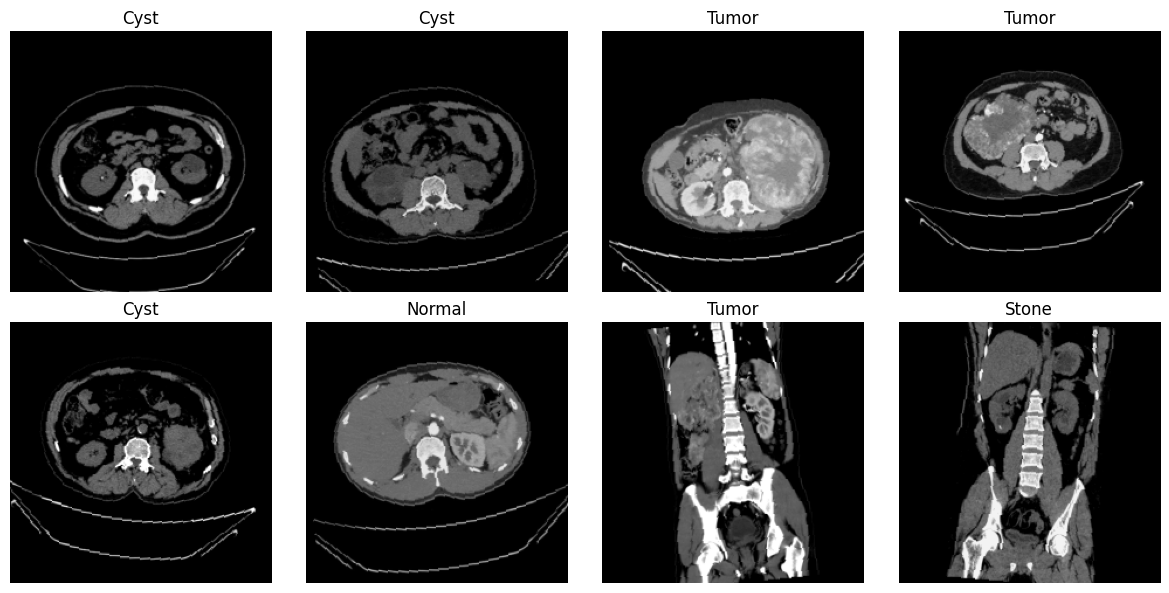

In [7]:
# 6. Visualize a few training samples

def denormalize(img_tensor):
    mean = torch.tensor(IMAGENET_MEAN, dtype=img_tensor.dtype).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD, dtype=img_tensor.dtype).view(3, 1, 1)
    return (img_tensor.cpu() * std + mean).clamp(0, 1)

sample_images, sample_labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    if i >= len(sample_images):
        ax.axis("off")
        continue
    img = denormalize(sample_images[i]).permute(1, 2, 0).numpy()
    ax.imshow(img, cmap="gray")
    ax.set_title(CLASS_NAMES[int(sample_labels[i])])
    ax.axis("off")
plt.tight_layout()
plt.show()
del sample_images, sample_labels


## 5. Class weights

Weights are calculated from the **training split only**. This reduces the influence of class imbalance without using validation or test labels to determine training weights.

In [8]:
# 7. Class weights
train_counts = np.bincount(train_dataset.targets, minlength=NUM_CLASSES)
if np.any(train_counts == 0):
    raise ValueError("At least one class has no training images; cannot calculate class weights.")

class_weights = len(train_dataset) / (NUM_CLASSES * torch.tensor(train_counts, dtype=torch.float32))
class_weights = class_weights.to(device)
print("Training counts:", dict(zip(CLASS_NAMES, train_counts.tolist())))
print("Loss weights:", {name: round(float(w), 4) for name, w in zip(CLASS_NAMES, class_weights.cpu())})


Training counts: {'Cyst': 2596, 'Normal': 3553, 'Stone': 963, 'Tumor': 1598}
Loss weights: {'Cyst': 0.8388, 'Normal': 0.6129, 'Stone': 2.2612, 'Tumor': 1.3626}


## 6. Build ResNet50

The notebook uses ImageNet-pretrained ResNet50 weights when they are available. If Kaggle cannot download the weights, it falls back to random initialization and prints a warning. For best transfer-learning performance, enable internet in Kaggle notebook settings or ensure the weights are available in the environment.

In [9]:
# 8. Model
try:
    weights = models.ResNet50_Weights.IMAGENET1K_V2
    model = models.resnet50(weights=weights)
    print("Loaded ImageNet-pretrained ResNet50 weights.")
except Exception as exc:
    print("WARNING: Could not load pretrained ResNet50 weights.")
    print("Reason:", repr(exc))
    print("The model will train from random initialization; results may be weaker.")
    model = models.resnet50(weights=None)

# Freeze the backbone for Phase 1.
for param in model.parameters():
    param.requires_grad = False

in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.35),
    nn.Linear(in_features, NUM_CLASSES),
)

# channels_last can improve convolution throughput on NVIDIA GPUs.
if device.type == "cuda":
    model = model.to(device=device, memory_format=torch.channels_last)
else:
    model = model.to(device)

print(model.fc)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 200MB/s] 


Loaded ImageNet-pretrained ResNet50 weights.
Sequential(
  (0): Dropout(p=0.35, inplace=False)
  (1): Linear(in_features=2048, out_features=4, bias=True)
)
Trainable parameters: 8196


## 7. Training utilities

The loop tracks macro-F1 as well as loss and accuracy, uses automatic mixed precision on CUDA, and writes a checkpoint after every epoch. Batch-normalization running statistics stay frozen during transfer learning to reduce instability on relatively small datasets.

In [10]:
# 9. Training and evaluation functions
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
criterion = nn.CrossEntropyLoss(weight=class_weights)


def set_training_mode(model, freeze_backbone=False):
    if freeze_backbone:
        # Keep the pretrained feature extractor fully in eval mode; train only fc.
        model.eval()
        model.fc.train()
    else:
        model.train()
        # Keep BatchNorm running means/variances fixed while fine-tuning.
        for module in model.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()


def run_epoch(model, loader, criterion, optimizer=None, freeze_backbone=False):
    is_train = optimizer is not None
    if is_train:
        set_training_mode(model, freeze_backbone=freeze_backbone)
    else:
        model.eval()

    total_loss = 0.0
    total_samples = 0
    all_preds = []
    all_targets = []

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for batch_images, batch_labels in loader:
            batch_images = batch_images.to(device, non_blocking=True)
            batch_labels = batch_labels.to(device, non_blocking=True)
            if device.type == "cuda":
                batch_images = batch_images.contiguous(memory_format=torch.channels_last)

            if is_train:
                optimizer.zero_grad(set_to_none=True)

            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                logits = model(batch_images)
                loss = criterion(logits, batch_labels)

            if is_train:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            batch_size = batch_images.size(0)
            total_loss += loss.detach().item() * batch_size
            total_samples += batch_size
            all_preds.append(logits.detach().argmax(dim=1).cpu())
            all_targets.append(batch_labels.detach().cpu())

    y_pred = torch.cat(all_preds).numpy()
    y_true = torch.cat(all_targets).numpy()
    mean_loss = total_loss / max(total_samples, 1)
    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    return mean_loss, accuracy, macro_f1


def train_model(model, train_loader, val_loader, criterion, optimizer,
                num_epochs, phase_name, freeze_backbone=False, scheduler=None,
                patience=3):
    best_val_f1 = -1.0
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    history = {
        "phase": [], "epoch": [], "train_loss": [], "train_acc": [],
        "train_macro_f1": [], "val_loss": [], "val_acc": [], "val_macro_f1": [],
        "epoch_seconds": []
    }
    checkpoint_path = OUTPUT_DIR / f"latest_{phase_name}_checkpoint.pth"
    best_path = OUTPUT_DIR / f"best_{phase_name}_checkpoint.pth"

    for epoch in range(num_epochs):
        start_time = time.time()
        train_loss, train_acc, train_f1 = run_epoch(
            model, train_loader, criterion, optimizer=optimizer,
            freeze_backbone=freeze_backbone
        )
        val_loss, val_acc, val_f1 = run_epoch(
            model, val_loader, criterion, optimizer=None
        )

        if scheduler is not None:
            scheduler.step(val_loss)

        elapsed = time.time() - start_time
        history["phase"].append(phase_name)
        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["train_macro_f1"].append(train_f1)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_macro_f1"].append(val_f1)
        history["epoch_seconds"].append(elapsed)

        print(
            f"{phase_name} | Epoch {epoch+1}/{num_epochs} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} train_F1={train_f1:.4f} | "
            f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} val_F1={val_f1:.4f} | "
            f"{elapsed:.1f}s"
        )

        # Save latest state every epoch, so the work is not lost if the session stops.
        latest_payload = {
            "phase": phase_name,
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "class_names": CLASS_NAMES,
            "img_size": IMG_SIZE,
            "history": history,
        }
        torch.save(latest_payload, checkpoint_path)

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
            torch.save({
                "phase": phase_name,
                "epoch": epoch + 1,
                "model_state_dict": best_state,
                "class_names": CLASS_NAMES,
                "img_size": IMG_SIZE,
                "best_val_macro_f1": best_val_f1,
            }, best_path)
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f"Early stopping: validation macro-F1 did not improve for {patience} epochs.")
                break

    model.load_state_dict(best_state)
    print(f"Best {phase_name} validation macro-F1: {best_val_f1:.4f}")
    print("Latest checkpoint:", checkpoint_path)
    print("Best checkpoint:", best_path)
    return model, history


## 8. Phase 1 — train the classifier head

The ResNet50 feature extractor is frozen in this phase. This is usually much faster than training the full network from the beginning.

In [12]:
# 10. Phase 1: frozen backbone
optimizer_head = optim.AdamW(
    (p for p in model.parameters() if p.requires_grad),
    lr=LR_HEAD,
    weight_decay=WEIGHT_DECAY,
)
scheduler_head = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_head, mode="min", factor=0.5, patience=2
)

model, history_head = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer_head,
    num_epochs=NUM_EPOCHS_HEAD,
    phase_name="head",
    freeze_backbone=True,
    scheduler=scheduler_head,
    patience=PATIENCE,
)


head | Epoch 1/6 | train_loss=0.8700 train_acc=0.7117 train_F1=0.6707 | val_loss=0.6733 val_acc=0.7905 val_F1=0.7622 | 658.6s
head | Epoch 2/6 | train_loss=0.5912 train_acc=0.8101 train_F1=0.7766 | val_loss=0.4831 val_acc=0.8665 val_F1=0.8343 | 72.6s
head | Epoch 3/6 | train_loss=0.5082 train_acc=0.8348 train_F1=0.8032 | val_loss=0.4008 val_acc=0.9015 val_F1=0.8771 | 71.6s
head | Epoch 4/6 | train_loss=0.4476 train_acc=0.8558 train_F1=0.8302 | val_loss=0.3825 val_acc=0.8963 val_F1=0.8720 | 72.1s
head | Epoch 5/6 | train_loss=0.4200 train_acc=0.8643 train_F1=0.8402 | val_loss=0.3270 val_acc=0.9208 val_F1=0.9035 | 72.2s
head | Epoch 6/6 | train_loss=0.3891 train_acc=0.8693 train_F1=0.8451 | val_loss=0.3152 val_acc=0.9256 val_F1=0.9086 | 71.8s
Best head validation macro-F1: 0.9086
Latest checkpoint: /kaggle/working/latest_head_checkpoint.pth
Best checkpoint: /kaggle/working/best_head_checkpoint.pth


## 9. Phase 2 — fine-tune the last ResNet block

Only `layer4` and the classifier head are unfrozen. The learning rate is much smaller than in Phase 1.

In [13]:
# 11. Phase 2: unfreeze layer4 and classifier
for name, param in model.named_parameters():
    if name.startswith("layer4.") or name.startswith("fc."):
        param.requires_grad = True

print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

optimizer_ft = optim.AdamW(
    (p for p in model.parameters() if p.requires_grad),
    lr=LR_FINETUNE,
    weight_decay=WEIGHT_DECAY,
)
scheduler_ft = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_ft, mode="min", factor=0.5, patience=2
)

model, history_ft = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer_ft,
    num_epochs=NUM_EPOCHS_FINETUNE,
    phase_name="finetune",
    freeze_backbone=False,
    scheduler=scheduler_ft,
    patience=PATIENCE,
)


Trainable parameters: 14972932
finetune | Epoch 1/6 | train_loss=0.2480 train_acc=0.9141 train_F1=0.8951 | val_loss=0.1021 val_acc=0.9719 val_F1=0.9638 | 72.1s
finetune | Epoch 2/6 | train_loss=0.1195 train_acc=0.9605 train_F1=0.9504 | val_loss=0.0579 val_acc=0.9859 val_F1=0.9812 | 72.3s
finetune | Epoch 3/6 | train_loss=0.0632 train_acc=0.9804 train_F1=0.9758 | val_loss=0.0456 val_acc=0.9863 val_F1=0.9819 | 72.0s
finetune | Epoch 4/6 | train_loss=0.0420 train_acc=0.9860 train_F1=0.9824 | val_loss=0.0172 val_acc=0.9972 val_F1=0.9960 | 73.5s
finetune | Epoch 5/6 | train_loss=0.0289 train_acc=0.9922 train_F1=0.9901 | val_loss=0.0114 val_acc=0.9976 val_F1=0.9967 | 72.9s
finetune | Epoch 6/6 | train_loss=0.0244 train_acc=0.9914 train_F1=0.9887 | val_loss=0.0162 val_acc=0.9960 val_F1=0.9950 | 72.4s
Best finetune validation macro-F1: 0.9967
Latest checkpoint: /kaggle/working/latest_finetune_checkpoint.pth
Best checkpoint: /kaggle/working/best_finetune_checkpoint.pth


In [14]:
# 12. Save final model and training history
FINAL_MODEL_PATH = OUTPUT_DIR / "kidney_resnet50_classifier.pth"
CHECKPOINT = {
    "architecture": "resnet50",
    "model_state_dict": model.state_dict(),
    "class_names": CLASS_NAMES,
    "img_size": IMG_SIZE,
    "imagenet_mean": IMAGENET_MEAN,
    "imagenet_std": IMAGENET_STD,
}
torch.save(CHECKPOINT, FINAL_MODEL_PATH)

history_all = pd.concat(
    [pd.DataFrame(history_head), pd.DataFrame(history_ft)],
    ignore_index=True,
)
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"
history_all.to_csv(HISTORY_PATH, index=False)

print("Final model saved:", FINAL_MODEL_PATH)
print("Training history saved:", HISTORY_PATH)


Final model saved: /kaggle/working/kidney_resnet50_classifier.pth
Training history saved: /kaggle/working/training_history.csv


## 10. Training curves

Review both training and validation curves. A large gap between training and validation performance can indicate overfitting.

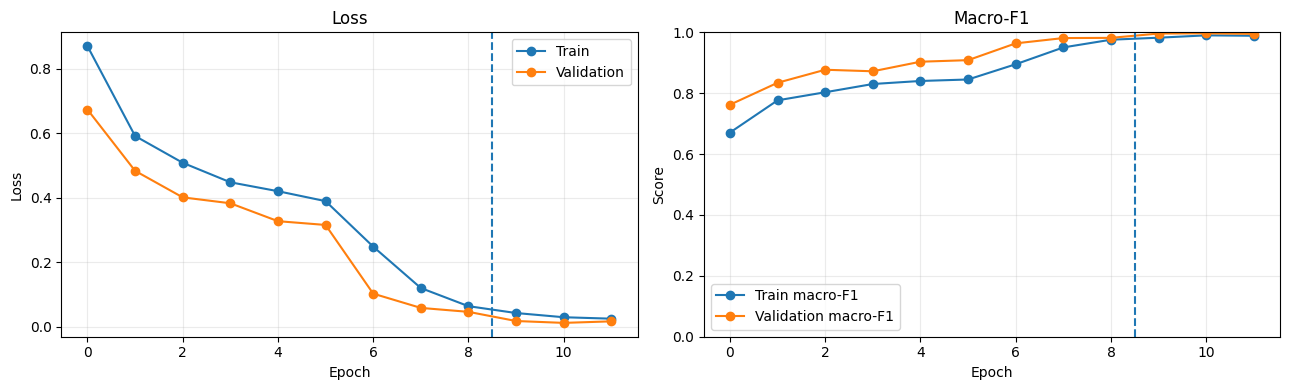

In [15]:
# 13. Plot training history

def plot_training_history(history_df):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(history_df["train_loss"].values, marker="o", label="Train")
    axes[0].plot(history_df["val_loss"].values, marker="o", label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(alpha=0.25)

    axes[1].plot(history_df["train_macro_f1"].values, marker="o", label="Train macro-F1")
    axes[1].plot(history_df["val_macro_f1"].values, marker="o", label="Validation macro-F1")
    axes[1].set_title("Macro-F1")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Score")
    axes[1].set_ylim(0, 1)
    axes[1].legend()
    axes[1].grid(alpha=0.25)

    phase_boundary = len(history_head)
    for ax in axes:
        if 0 < phase_boundary < len(history_df):
            ax.axvline(phase_boundary - 0.5, linestyle="--", label="Fine-tuning starts")
    plt.tight_layout()
    plt.show()

plot_training_history(history_all)


## 11. Final evaluation on the held-out test set

The test split is used only after training and model selection. Report class-wise precision, recall, and F1—not accuracy alone. For a medical-imaging research study, tumor recall and the confusion matrix deserve particular attention.

In [16]:
# 14. Test set predictions and metrics
model.eval()
all_probs = []
all_preds = []
all_labels = []

with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        batch_images = batch_images.to(device, non_blocking=True)
        if device.type == "cuda":
            batch_images = batch_images.contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(batch_images)
        probs = torch.softmax(logits.float(), dim=1)
        all_probs.append(probs.cpu().numpy())
        all_preds.append(probs.argmax(dim=1).cpu().numpy())
        all_labels.append(batch_labels.numpy())

all_probs = np.concatenate(all_probs, axis=0)
all_preds = np.concatenate(all_preds, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

print(f"Test accuracy: {accuracy_score(all_labels, all_preds):.4f}")
print(f"Test macro-F1: {f1_score(all_labels, all_preds, average='macro', zero_division=0):.4f}")
try:
    macro_auc = roc_auc_score(
        all_labels,
        all_probs,
        labels=list(range(NUM_CLASSES)),
        multi_class="ovr",
        average="macro",
    )
    print(f"Test macro ROC-AUC (OvR): {macro_auc:.4f}")
except ValueError as exc:
    print("ROC-AUC could not be calculated:", exc)

print("\nClassification report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
))

precision, recall, f1, support = precision_recall_fscore_support(
    all_labels, all_preds, labels=list(range(NUM_CLASSES)), zero_division=0
)
metrics_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "support": support,
})
metrics_path = OUTPUT_DIR / "test_class_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)
print("Per-class metrics saved:", metrics_path)


Test accuracy: 0.9968
Test macro-F1: 0.9961
Test macro ROC-AUC (OvR): 1.0000

Classification report:
              precision    recall  f1-score   support

        Cyst     0.9946    0.9973    0.9960       371
      Normal     0.9961    1.0000    0.9980       509
       Stone     1.0000    0.9856    0.9928       139
       Tumor     1.0000    0.9956    0.9978       229

    accuracy                         0.9968      1248
   macro avg     0.9977    0.9946    0.9961      1248
weighted avg     0.9968    0.9968    0.9968      1248

Per-class metrics saved: /kaggle/working/test_class_metrics.csv


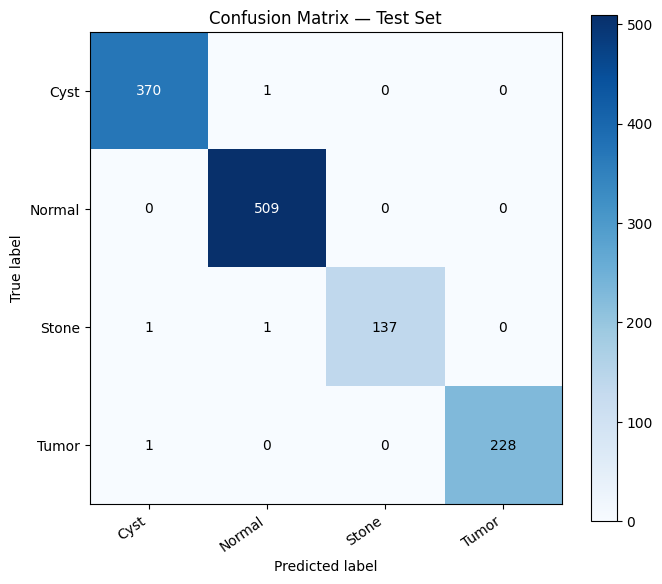

In [17]:
# 15. Confusion matrix
cm = confusion_matrix(all_labels, all_preds, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASS_NAMES, rotation=35, ha="right")
ax.set_yticks(range(NUM_CLASSES))
ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Confusion Matrix — Test Set")
threshold = cm.max() / 2 if cm.size else 0
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "test_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()


## 12. Grad-CAM explainability check

This section uses a small Grad-CAM implementation without installing an extra package. Check whether the highlighted regions correspond to meaningful kidney anatomy rather than image borders, labels, or scanner artifacts. A plausible-looking heatmap does **not** establish clinical validity.

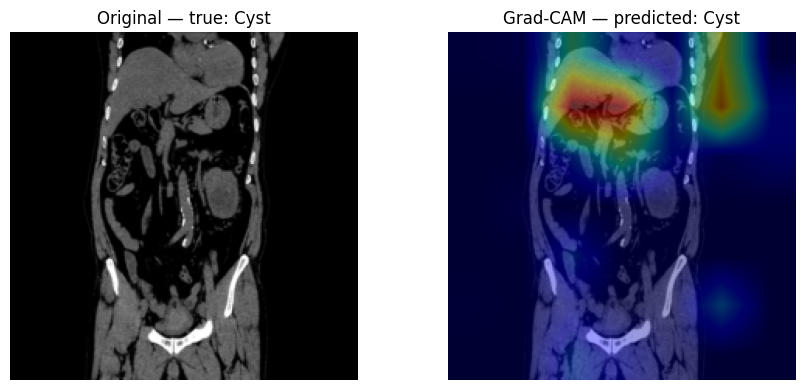

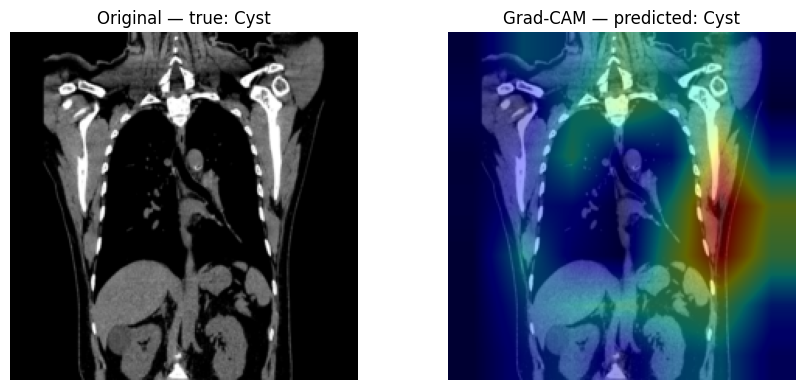

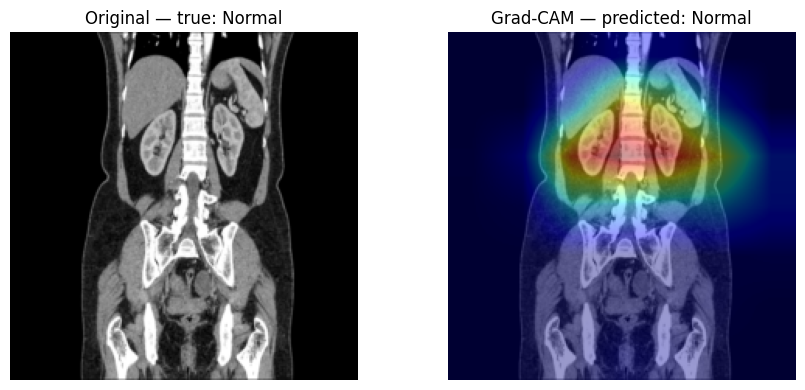

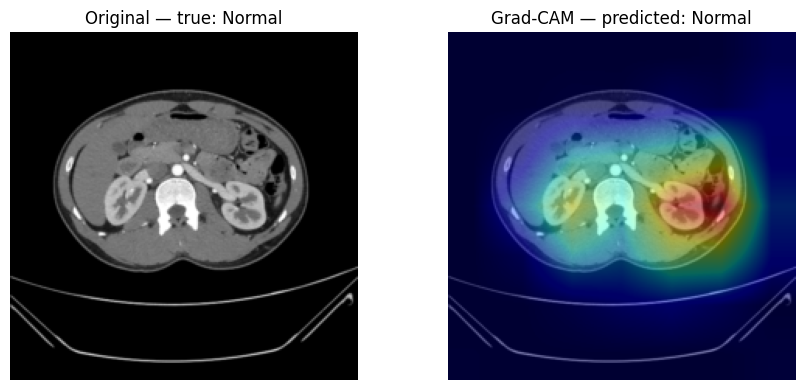

In [18]:
# 16. Grad-CAM for ResNet50 layer4

def show_gradcam(dataset, index):
    model.eval()
    image_tensor, true_label = dataset[index]
    input_tensor = image_tensor.unsqueeze(0).to(device)
    if device.type == "cuda":
        input_tensor = input_tensor.contiguous(memory_format=torch.channels_last)

    cache = {}

    def forward_hook(module, inputs, output):
        cache["activations"] = output
        output.register_hook(lambda grad: cache.__setitem__("gradients", grad))

    hook_handle = model.layer4[-1].register_forward_hook(forward_hook)
    model.zero_grad(set_to_none=True)

    try:
        with torch.autocast(device_type=device.type, enabled=False):
            logits = model(input_tensor.float())
            predicted_label = int(logits.argmax(dim=1).item())
            score = logits[0, predicted_label]
        score.backward()
    finally:
        hook_handle.remove()

    activations = cache["activations"].detach()
    gradients = cache["gradients"].detach()
    weights = gradients.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * activations).sum(dim=1, keepdim=True))
    cam = torch.nn.functional.interpolate(
        cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False
    )[0, 0]
    cam = cam.cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    original = denormalize(image_tensor).permute(1, 2, 0).numpy()
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(original, cmap="gray")
    axes[0].set_title(f"Original — true: {CLASS_NAMES[int(true_label)]}")
    axes[0].axis("off")
    axes[1].imshow(original, cmap="gray")
    axes[1].imshow(cam, cmap="jet", alpha=0.4)
    axes[1].set_title(f"Grad-CAM — predicted: {CLASS_NAMES[predicted_label]}")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

# Four randomly selected test images
n_examples = min(4, len(test_dataset))
for idx in random.sample(range(len(test_dataset)), n_examples):
    show_gradcam(test_dataset, idx)


## 13. Predict one image

Use this helper to test a single image file. It returns the predicted class and the model's class scores. These scores are not calibrated clinical probabilities.

In [20]:
# 17. Single-image prediction helper
from PIL import Image

single_image_transform = eval_transform


def predict_image(image_path):
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    image = Image.open(image_path).convert("RGB")
    tensor = single_image_transform(image).unsqueeze(0).to(device)
    if device.type == "cuda":
        tensor = tensor.contiguous(memory_format=torch.channels_last)

    model.eval()
    with torch.no_grad():
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(tensor)
        scores = torch.softmax(logits.float(), dim=1)[0].cpu().numpy()

    result = pd.DataFrame({"class": CLASS_NAMES, "score": scores})
    result = result.sort_values("score", ascending=False).reset_index(drop=True)
    print("Top predicted class:", result.loc[0, "class"])
    return result

# Example:
# predict_image("/kaggle/input/your-dataset/example.png")


## 14. Limitations and reporting notes

- **Not for clinical use:** this is an experimental image-classification pipeline, not a validated diagnostic system.
- **Patient-level leakage:** if multiple CT slices from one patient are present, split data by patient—not by individual image—before training. Otherwise, near-duplicate slices may occur in train and test and inflate performance.
- **External validation:** a held-out test split from the same dataset does not establish generalization to other hospitals, scanners, protocols, or populations.
- **Class imbalance:** include class-wise recall and F1 in any report. Overall accuracy can conceal poor performance on a minority class.
- **Label quality:** verify the source of labels and whether images represent comparable views and acquisition protocols.
- **Explainability:** Grad-CAM is a debugging aid, not proof that the model reasons correctly.
- **Uncertainty:** consider patient-level confidence intervals, repeated seeds, and external validation before making research claims.

### Output files

After the notebook runs, check `/kaggle/working/` for:

- `kidney_resnet50_classifier.pth` — final PyTorch model checkpoint
- `best_head_checkpoint.pth` and `best_finetune_checkpoint.pth` — best phase checkpoints
- `latest_head_checkpoint.pth` and `latest_finetune_checkpoint.pth` — most recent epoch checkpoints
- `training_history.csv` — training/validation history
- `test_class_metrics.csv` — per-class test metrics
- `test_confusion_matrix.png` — confusion matrix image

To download them, open the **Output** panel in Kaggle and use the file menu, or save a notebook version after execution.

In [22]:
import shutil

zip_path = shutil.make_archive(
    "/kaggle/working/kidney_project_outputs",
    "zip",
    root_dir="/kaggle/working"
)

print("Download package created:", zip_path)

OSError: [Errno 28] No space left on device